# Advance Bank Term Deposit

## Introduction
This notebook provides a detailed analysis of customer behavior and insights into factors influencing term deposit subscription.

## Load Dataset

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("../data/data.csv")
print(df.head())

# Dataset info and missing values
print('=== Dataset Info ===')
df.info()
print('\n=== Missing Values ===')
print(df.isnull().sum().sum(), 'missing values total')
print('\n=== Basic Statistics ===')
df.describe()

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


## Customer Demographics Analysis

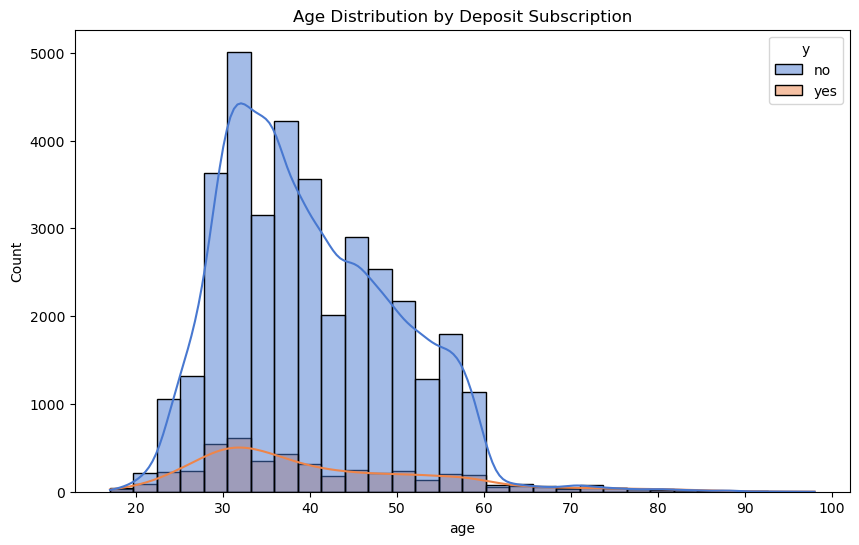

In [4]:
# Age distribution

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='age', hue='y', bins=30, kde=True, palette='muted')
plt.title('Age Distribution by Deposit Subscription')
plt.show()

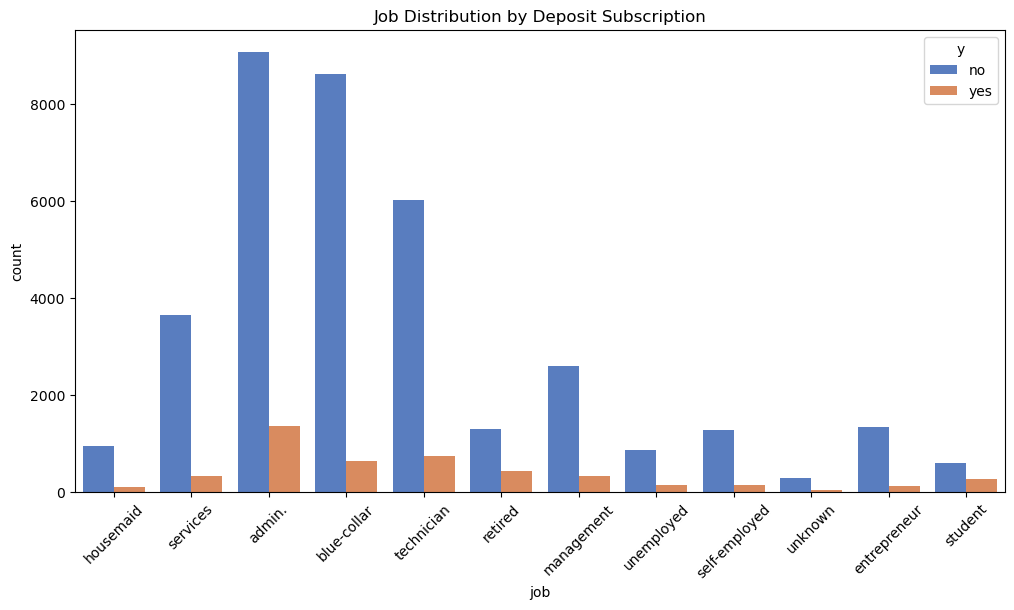

In [5]:
# Job distribution

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='job', hue='y', palette='muted')
plt.xticks(rotation=45)
plt.title('Job Distribution by Deposit Subscription')
plt.show()

## Balance & Deposit Trends

C:\Users\ASUS EXPERT\AppData\Local\Temp\ipykernel_3036\2226882998.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='y', y='duration', palette='muted')


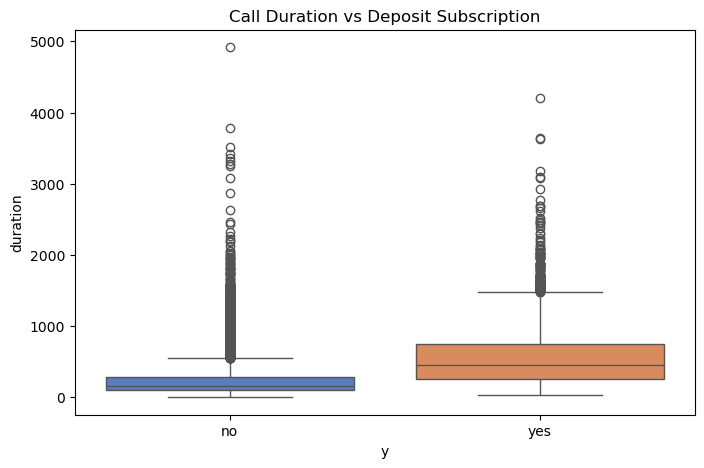

y
no     220.844807
yes    553.191164
Name: duration, dtype: float64


In [6]:
# Average balance by deposit subscription

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='y', y='duration', palette='muted')
plt.title('Call Duration vs Deposit Subscription')
plt.show()

print(df.groupby('y')['duration'].mean())

## Campaign Effectiveness

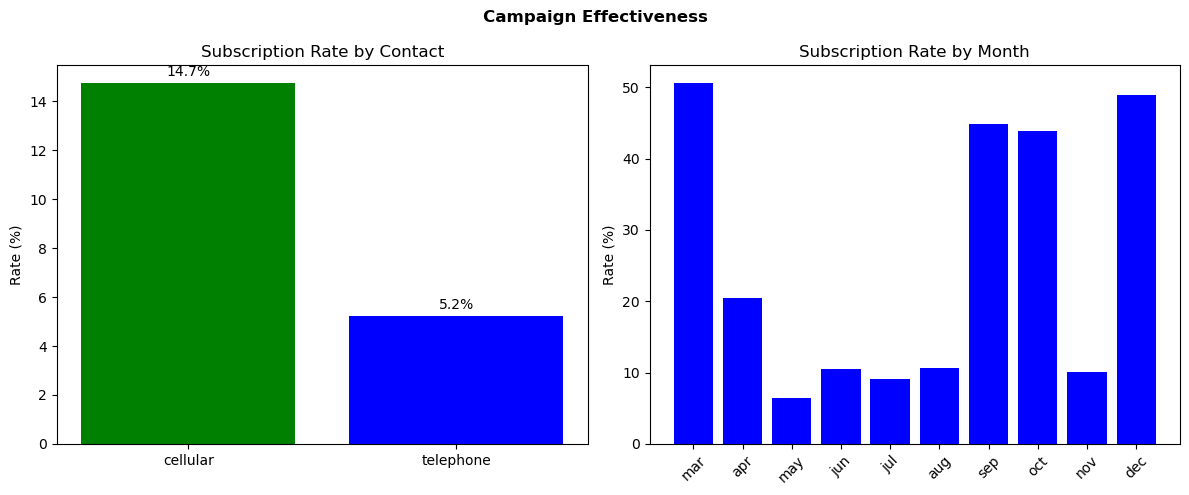

In [7]:
# Contact method analysis

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Campaign Effectiveness', fontweight='bold')

# 1. Contact Method
contact_rate = df.groupby('contact')['y'].apply(lambda x: (x == 'yes').mean() * 100)
bars = axes[0].bar(contact_rate.index, contact_rate.values, color=['green', 'blue'])
axes[0].set(title='Subscription Rate by Contact', ylabel='Rate (%)')
axes[0].bar_label(bars, fmt='%.1f%%', padding=3) # Replaces the complex loop

# 2. Monthly Rate
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_rate = df.groupby('month')['y'].apply(lambda x: (x == 'yes').mean() * 100).reindex(months).dropna()

axes[1].bar(month_rate.index, month_rate.values, color='blue')
axes[1].set(title='Subscription Rate by Month', ylabel='Rate (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

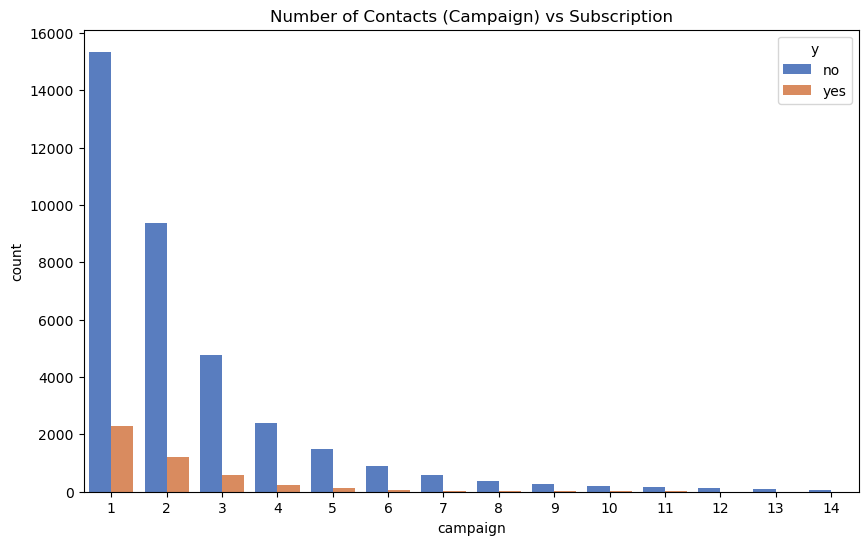

In [8]:
# Number of contacts vs deposit subscription

plt.figure(figsize=(10, 6))
# Filtering out extreme outliers in campaign contacts for better visualization
sns.countplot(data=df[df['campaign'] < 15], x='campaign', hue='y', palette='muted')
plt.title('Number of Contacts (Campaign) vs Subscription')
plt.show()

## Correlation Heatmap

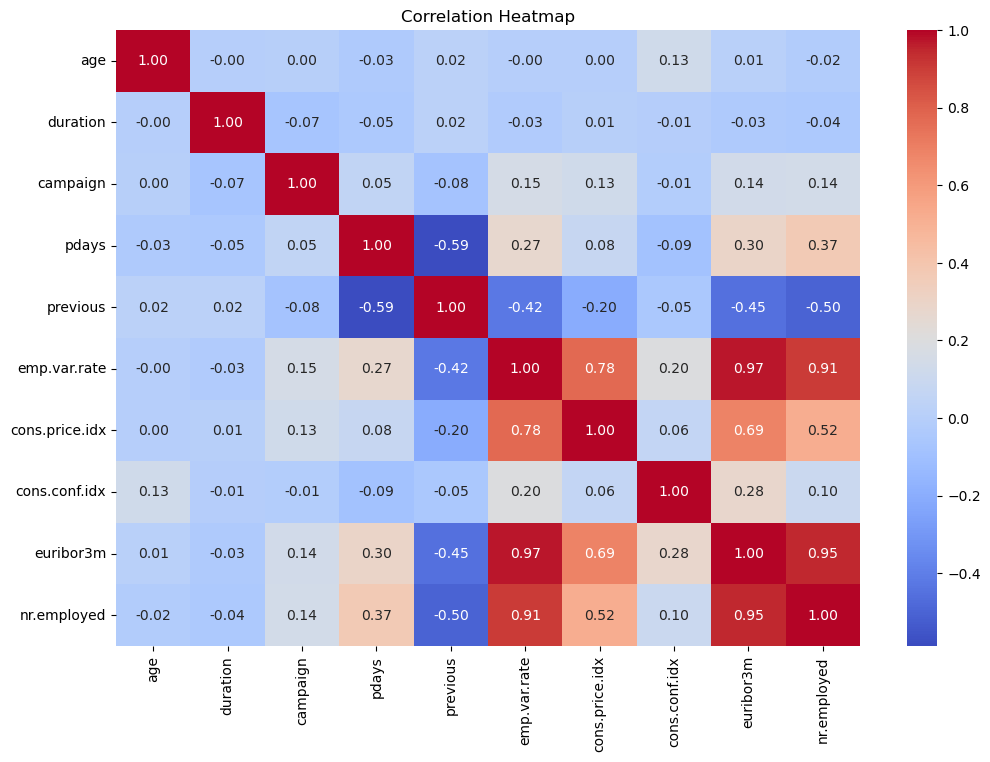

In [9]:
# Correlation of numerical variables
# Correlation of numerical variables
plt.figure(figsize=(12, 8))
# Select only numerical columns for the heatmap
numerical_df = df.select_dtypes(include=['int64', 'float64'])
corr = numerical_df.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


## Predictive Modeling (Logistic Regression)

In [10]:


# Encode categorical variablesfrom sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Encode categorical variables
df_model = df.copy()
cat_cols = ['job','marital','education','default','housing','loan',
            'contact','month','day_of_week','poutcome']
le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col].astype(str))
df_model['y_bin'] = (df_model['y']=='yes').astype(int)

feature_cols = ['age','job','marital','education','default','housing','loan','contact',
                'duration','campaign','pdays','previous','poutcome',
                'emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
X = df_model[feature_cols]
y_target = df_model['y_bin']

X_train, X_test, y_train, y_test = train_test_split(
    X, y_target, test_size=0.2, random_state=42, stratify=y_target)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# Train model with class_weight='balanced' to handle imbalance
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train_s, y_train)

# Predictions
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

roc = roc_auc_score(y_test, y_prob)
print(f'ROC-AUC Score: {roc:.4f}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['No','Yes']))




ROC-AUC Score: 0.9365

Classification Report:
              precision    recall  f1-score   support

          No       0.98      0.85      0.91      7310
         Yes       0.43      0.88      0.58       928

    accuracy                           0.86      8238
   macro avg       0.71      0.87      0.75      8238
weighted avg       0.92      0.86      0.88      8238



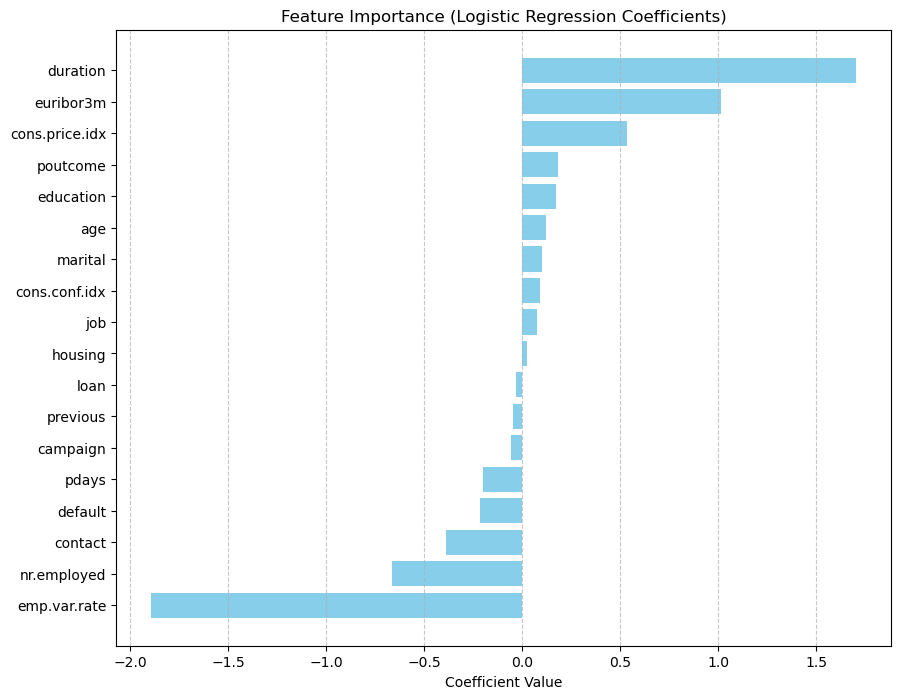

In [11]:
# Feature importance
import numpy as np

importance = model.coef_[0]
features = X.columns
indices = np.argsort(importance)

plt.figure(figsize=(10, 8))
plt.title("Feature Importance (Logistic Regression Coefficients)")
plt.barh(range(len(indices)), importance[indices], align="center", color='skyblue')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel("Coefficient Value")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

## Key Takeaways
Customer demographics play a role in term deposit subscriptions.

Longer calls help get more customers to subscribe.

Customers with money in their accounts are more likely to subscribe to term deposits.

Contacting customers by cell phone works better, than using a telephone.

How often we run campaigns affects how customers respond and how successful we are.

Using Logistic Regression can help us figure out who will subscribe to term deposits.